In [2]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline


df = sns.load_dataset("titanic")

In [3]:
df_utile = df[[ "survived","pclass","sex","age",]].copy()
print(df_utile.head())

   survived  pclass     sex   age
0         0       3    male  22.0
1         1       1  female  38.0
2         1       3  female  26.0
3         1       1  female  35.0
4         0       3    male  35.0


In [4]:
print(df_utile.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
dtypes: float64(1), int64(2), object(1)
memory usage: 28.0+ KB
None


In [5]:
df_utile["sex"] = df_utile["sex"].str.lower()
df_utile["sex"] = (df_utile["sex"] == "male").astype(int)
print(df_utile.head())


   survived  pclass  sex   age
0         0       3    1  22.0
1         1       1    0  38.0
2         1       3    0  26.0
3         1       1    0  35.0
4         0       3    1  35.0


In [6]:
print(df_utile.isnull().sum())
pourcentage_age_manquant = df_utile["age"].isnull().mean()
print("Pourcentage de valeurs manquantes pour la colonne 'age' :", round(pourcentage_age_manquant * 100, 2), "%")

survived      0
pclass        0
sex           0
age         177
dtype: int64
Pourcentage de valeurs manquantes pour la colonne 'age' : 19.87 %


In [7]:
print(df_utile["age"].isnull().groupby(df_utile["pclass"]).sum())
print(df_utile["age"].isnull().groupby(df_utile["pclass"]).mean()*100)

pclass
1     30
2     11
3    136
Name: age, dtype: int64
pclass
1    13.888889
2     5.978261
3    27.698574
Name: age, dtype: float64


In [8]:
print(df_utile.groupby("pclass")["age"].agg(["mean", "median"]).round(1))

        mean  median
pclass              
1       38.2    37.0
2       29.9    29.0
3       25.1    24.0


In [9]:
df_utile["age"] = df_utile["age"].fillna(df_utile.groupby("pclass")["age"].transform("median"))
print(df_utile.isnull().sum())

survived    0
pclass      0
sex         0
age         0
dtype: int64


In [10]:
print(df_utile["age"].unique())
print("______________________________________")
print(df_utile["pclass"].unique())
print("______________________________________")
print(df_utile["survived"].unique())




[22.   38.   26.   35.   24.   54.    2.   27.   14.    4.   58.   20.
 39.   55.   29.   31.   34.   15.   28.    8.   19.   40.   37.   66.
 42.   21.   18.    3.    7.   49.   65.   28.5   5.   11.   45.   17.
 32.   16.   25.    0.83 30.   33.   23.   46.   59.   71.   47.   14.5
 70.5  32.5  12.    9.   36.5  51.   55.5  40.5  44.    1.   61.   56.
 50.   36.   45.5  20.5  62.   41.   52.   63.   23.5   0.92 43.   60.
 10.   64.   13.   48.    0.75 53.   57.   80.   70.   24.5   6.    0.67
 30.5   0.42 34.5  74.  ]
______________________________________
[3 1 2]
______________________________________
[0 1]


In [11]:
x = df_utile[["pclass","sex","age"]]
y = df_utile["survived"]

x_train , x_test ,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42,stratify=y)
scaler = StandardScaler()
x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

for k in [1, 3, 5, 7, 9, 11, 15, 21, 31, 51] :
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train_scaler,y_train)
    y_pred = knn.predict(x_test_scaler)
    exactitude_scaled = (y_pred == y_test).mean()
    detectees_scaled = (y_pred & y_test).sum()
    print(f"Exactitude pour k={k} :", round(exactitude_scaled, 3))
    print(f"survivant détectées pour k={k} :", detectees_scaled, "sur", y_test.sum())
    

Exactitude pour k=1 : 0.772
survivant détectées pour k=1 : 73 sur 103
Exactitude pour k=3 : 0.802
survivant détectées pour k=3 : 74 sur 103
Exactitude pour k=5 : 0.802
survivant détectées pour k=5 : 74 sur 103
Exactitude pour k=7 : 0.825
survivant détectées pour k=7 : 75 sur 103
Exactitude pour k=9 : 0.791
survivant détectées pour k=9 : 68 sur 103
Exactitude pour k=11 : 0.799
survivant détectées pour k=11 : 68 sur 103
Exactitude pour k=15 : 0.787
survivant détectées pour k=15 : 68 sur 103
Exactitude pour k=21 : 0.784
survivant détectées pour k=21 : 68 sur 103
Exactitude pour k=31 : 0.765
survivant détectées pour k=31 : 66 sur 103
Exactitude pour k=51 : 0.776
survivant détectées pour k=51 : 70 sur 103


k=1 : moyenne = 0.735
k=3 : moyenne = 0.786
k=5 : moyenne = 0.811
k=7 : moyenne = 0.793
k=9 : moyenne = 0.788
k=11 : moyenne = 0.793
k=15 : moyenne = 0.796
k=21 : moyenne = 0.806
k=31 : moyenne = 0.801
k=51 : moyenne = 0.786
____________________________________________________________________


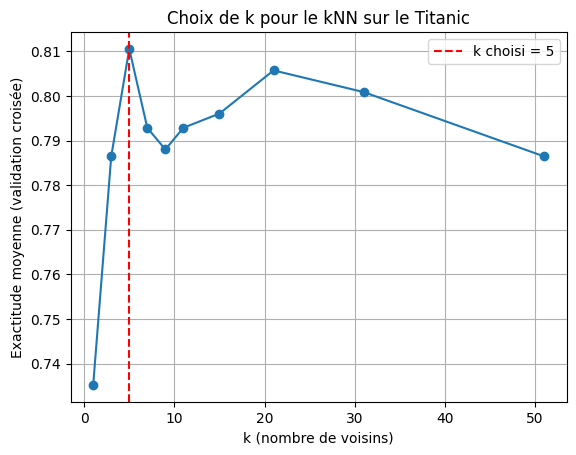

In [12]:
liste_k = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]
moyennes = []
for k in liste_k :
    modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(modele, x_train, y_train, cv=5)
    moyennes.append(scores.mean())
    print(f"k={k} : moyenne = {scores.mean():.3f}")

print("____________________________________________________________________")

plt.plot(liste_k,moyennes,marker ="o")
plt.xlabel("k (nombre de voisins)")
plt.ylabel("Exactitude moyenne (validation croisée)")
plt.title("Choix de k pour le kNN sur le Titanic")
plt.grid(True)
plt.axvline(x=5, color="red", linestyle="--", label="k choisi = 5")
plt.legend()
plt.show()




In [13]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaler,y_train)
y_pred = knn.predict(x_test_scaler)
nouveau = pd.DataFrame({"pclass": [3], "sex": [1], "age": [35]})
nouveau_scaler = scaler.transform(nouveau)
print(knn.predict(nouveau_scaler))

[0]
